# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser

**Scenario.** An agricultural extension officer wants to compare rainfall regimes across regions and advise farmers on which months suit which crops.

**Data.** This notebook uses **real monthly rainfall, 2010–2023 (14 years)**, for Kampala, Gulu and Mbarara from **NASA POWER** (`power.larc.nasa.gov`, parameter `PRECTOTCORR`, community `AG`), not the assignment's illustrative single-year figures — the extension-credit data source, used from the start rather than only in the extension. NASA POWER reports an average daily rate (mm/day) per month; this notebook converts that to a monthly total (mm) by multiplying by the number of days in that month. The fetch and conversion script is reproducible; see `data/rainfall_2010_2023.csv`.

Reusable logic lives in `src/rainfall.py` (`Region`, `CropRule`, and helper functions).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from src.rainfall import (
    MONTH_NAMES,
    CropRule,
    Region,
    cosine_similarity,
    find_rainy_seasons,
    similarity_matrices,
    suitability_table,
)

# Colorblind-safe categorical palette (Okabe & Ito, 2008), fixed order per region.
REGION_COLORS = {"Kampala": "#0072B2", "Gulu": "#D55E00", "Mbarara": "#009E73"}
STATUS_COLORS = {"Drought risk": "#D55E00", "Good": "#009E73", "Waterlogging risk": "#0072B2"}

In [2]:
raw = pd.read_csv("data/rainfall_2010_2023.csv")
raw.head()

,region,year,month,rainfall_mm
0,Kampala,2010,1,48.05
1,Kampala,2010,2,120.40
2,Kampala,2010,3,185.38
3,Kampala,2010,4,184.20
4,Kampala,2010,5,155.62


In [3]:
# 14-year mean monthly rainfall per region -> the 12-value profile used by Region/CropRule
monthly_mean = raw.pivot_table(index="month", columns="region", values="rainfall_mm", aggfunc="mean")
monthly_mean = monthly_mean.reindex(range(1, 13))
monthly_mean.index = MONTH_NAMES
monthly_mean

region,Gulu,Kampala,Mbarara
Jan,23.072857,49.887857,55.445714
Feb,11.709286,61.629286,65.864286
Mar,69.262857,156.682857,139.699286
Apr,130.135714,192.085714,150.964286
May,164.078571,160.402857,118.309286
Jun,111.214286,68.442857,46.307143
Jul,113.880714,41.739286,35.317857
Aug,148.113571,79.027857,103.318571
Sep,177.407143,132.064286,133.607143
Oct,204.422857,188.457857,143.220000


## Task 1 — `Region` class

In [4]:
regions = [Region(name, monthly_mean[name].to_numpy()) for name in ["Kampala", "Gulu", "Mbarara"]]
region_by_name = {r.name: r for r in regions}

for r in regions:
    print(r)
    print(f"  mean monthly: {r.mean():.1f} mm, CV: {r.coefficient_of_variation():.3f}")
    print(f"  wettest: {r.wettest_month()}, driest: {r.driest_month()}")

Region('Kampala', annual_total=1463.8mm)
  mean monthly: 122.0 mm, CV: 0.488
  wettest: ('Nov', 204.45000000000002), driest: ('Jul', 41.739285714285714)
Region('Gulu', annual_total=1315.6mm)
  mean monthly: 109.6 mm, CV: 0.551
  wettest: ('Oct', 204.42285714285714), driest: ('Feb', 11.709285714285715)
Region('Mbarara', annual_total=1239.6mm)
  mean monthly: 103.3 mm, CV: 0.412
  wettest: ('Apr', 150.96428571428572), driest: ('Jul', 35.31785714285714)


## Task 2 — `CropRule` and month-by-month classification

Thresholds are monthly-equivalent bands derived from published seasonal crop-water-requirement ranges (FAO Irrigation & Drainage Paper No. 56, Allen et al. 1998, and general East African agronomy guidance for maize, common bean and Robusta coffee — Uganda's dominant coffee variety). They are approximate, stated explicitly, and open to challenge:

- **Maize**: seasonal need ≈500–800 mm over a ~4-month cycle → good band ≈60–180 mm/month; below is drought risk, above risks waterlogging/nutrient leaching.
- **Beans**: seasonal need ≈300–500 mm over a ~3-month cycle, more drought-tolerant but waterlogging-sensitive → good band ≈50–150 mm/month.
- **Coffee (Robusta)**: a perennial tree crop needing ≈1200–2000 mm/year, well distributed, with deeper roots buffering short dry spells but vulnerable to root rot in prolonged waterlogging → good band ≈100–250 mm/month.

In [5]:
crops = [
    CropRule("maize", drought_max_mm=60, waterlog_min_mm=180, source="FAO ID-56 (Allen et al. 1998); EA agronomy guidance"),
    CropRule("beans", drought_max_mm=50, waterlog_min_mm=150, source="FAO ID-56; common bean seasonal water need ~300-500mm/90d"),
    CropRule("coffee", drought_max_mm=100, waterlog_min_mm=250, source="Robusta coffee annual need ~1200-2000mm, well distributed"),
]

table = suitability_table(regions, crops)
table[(table["region"] == "Kampala") & (table["crop"] == "maize")]

,region,month,month_num,crop,rainfall_mm,label
0,Kampala,Jan,1,maize,49.887857,Drought risk for maize
3,Kampala,Feb,2,maize,61.629286,Good for maize
6,Kampala,Mar,3,maize,156.682857,Good for maize
9,Kampala,Apr,4,maize,192.085714,Waterlogging risk for maize
12,Kampala,May,5,maize,160.402857,Good for maize
15,Kampala,Jun,6,maize,68.442857,Good for maize
18,Kampala,Jul,7,maize,41.739286,Drought risk for maize
21,Kampala,Aug,8,maize,79.027857,Good for maize
24,Kampala,Sep,9,maize,132.064286,Good for maize
27,Kampala,Oct,10,maize,188.457857,Waterlogging risk for maize


## Task 3 — Correcting the flawed cosine-similarity method

The previous cohort's question asked for cosine similarity via `math.cos()`. That computes the cosine of a single scalar *angle* (in radians) — a number in [-1, 1] with **no connection to how similar two rainfall vectors are**. For example `math.cos(dot_product)` would just be evaluating a trig function at an arbitrary large number, producing an oscillating, meaningless result. The correct formula is the cosine of the angle *between two vectors*: dot product divided by the product of their norms.

In [6]:
from scipy.spatial.distance import cosine as scipy_cosine

a, b = region_by_name["Kampala"].rainfall_mm, region_by_name["Gulu"].rainfall_mm
ours = cosine_similarity(a, b)
theirs = 1 - scipy_cosine(a, b)  # scipy returns the *distance* (1 - similarity)
print(f"Our cosine_similarity(Kampala, Gulu): {ours:.6f}")
print(f"1 - scipy.spatial.distance.cosine(...): {theirs:.6f}")
assert np.isclose(ours, theirs)
print("Verified: matches scipy.")

Our cosine_similarity(Kampala, Gulu): 0.894153
1 - scipy.spatial.distance.cosine(...): 0.894153
Verified: matches scipy.


## Task 4 — Three similarity/distance measures between every pair of regions

In [7]:
region_vectors = {r.name: r.rainfall_mm for r in regions}
matrices = similarity_matrices(region_vectors)

print("Cosine similarity:")
display(matrices["cosine"].round(3))
print("\nPearson correlation:")
display(matrices["pearson"].round(3))
print("\nEuclidean distance (mm):")
display(matrices["euclidean"].round(1))

Cosine similarity:


,Kampala,Gulu,Mbarara
Kampala,1.000,0.894,0.988
Gulu,0.894,1.000,0.906
Mbarara,0.988,0.906,1.000



Pearson correlation:


,Kampala,Gulu,Mbarara
Kampala,1.000,0.470,0.934
Gulu,0.470,1.000,0.484
Mbarara,0.934,0.484,1.000



Euclidean distance (mm):


,Kampala,Gulu,Mbarara
Kampala,0.0,209.2,104.9
Gulu,209.2,0.0,182.1
Mbarara,104.9,182.1,0.0


**Why cosine similarity can call two regions "similar" despite very different totals.** Cosine similarity only measures the *angle* between two vectors — the shape of their seasonal pattern — and is invariant to scaling: a region that is exactly twice as wet every month as another, with an identical seasonal shape, scores a cosine similarity of 1.0 even though its annual total is double. Pearson correlation is similarly scale- and offset-invariant (it also centres each vector by its mean first). Euclidean distance is the odd one out: it *does* care about absolute magnitude, so it can tell two regions with the same seasonal *shape* apart if their totals differ. Reading cosine similarity alongside Euclidean distance avoids the trap of calling two regions "similar" purely because they rise and fall together, when one is a much wetter place overall.

## Task 5 — Detecting rainy seasons with `scipy.signal.find_peaks`

In [8]:
for r in regions:
    result = find_rainy_seasons(r.rainfall_mm, prominence=20)
    peak_names = [MONTH_NAMES[m - 1] for m in result["peak_months"]]
    print(f"{r.name}: {result['pattern']} — peak month(s): {peak_names}")

Kampala: Bimodal — peak month(s): ['Apr', 'Nov']
Gulu: Bimodal — peak month(s): ['May', 'Oct']
Mbarara: Bimodal — peak month(s): ['Apr', 'Nov']


**Comparison with Uganda's known climate zones.** The textbook UNMA picture splits Uganda into a **bimodal** south/central Lake Victoria basin (two rainy seasons, roughly Mar–May and Sep–Nov) and a **unimodal** north (one long wet season, part of a more Sudanic single-peak belt). The 14-year NASA POWER mean here does **not** cleanly reproduce that simple two-zone story: all three regions — including Gulu — come back **Bimodal** at a peak-detection prominence of 20 mm. Kampala and Mbarara match the textbook bimodal pattern almost exactly (peaks in Apr and Nov). Gulu's two peaks (May and Oct) sit later in the year and are separated by a much shallower mid-year dip (Jun–Jul, ~111–114 mm, only ~50–90 mm below the surrounding peaks) than Kampala's sharp Jun–Aug dry trough — so while the peak detector still calls it bimodal, its rainy season reads far more like one long, gently double-humped wet season (Mar–Nov almost continuously "Good" for maize, see Task 7) than Kampala's two clearly separated seasons with a real dry gap between them. Two honest caveats: (1) this classification is sensitive to the prominence threshold chosen — a stricter one could re-classify Gulu as unimodal — and (2) averaging 14 years of data smooths out year-to-year shifts in the exact peak timing that a single illustrative year (like the assignment's original numbers) would not show at all.

## Task 6 — Visualisations

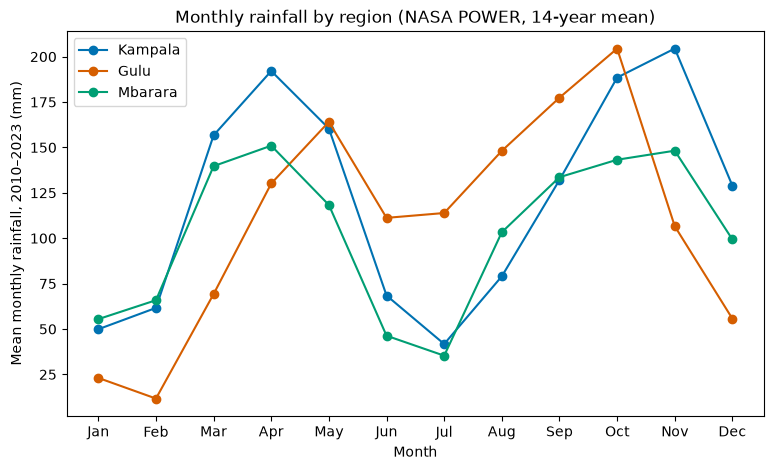

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
for r in regions:
    ax.plot(range(1, 13), r.rainfall_mm, marker="o", label=r.name, color=REGION_COLORS[r.name])
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTH_NAMES)
ax.set_xlabel("Month")
ax.set_ylabel("Mean monthly rainfall, 2010–2023 (mm)")
ax.set_title("Monthly rainfall by region (NASA POWER, 14-year mean)")
ax.legend()
plt.show()

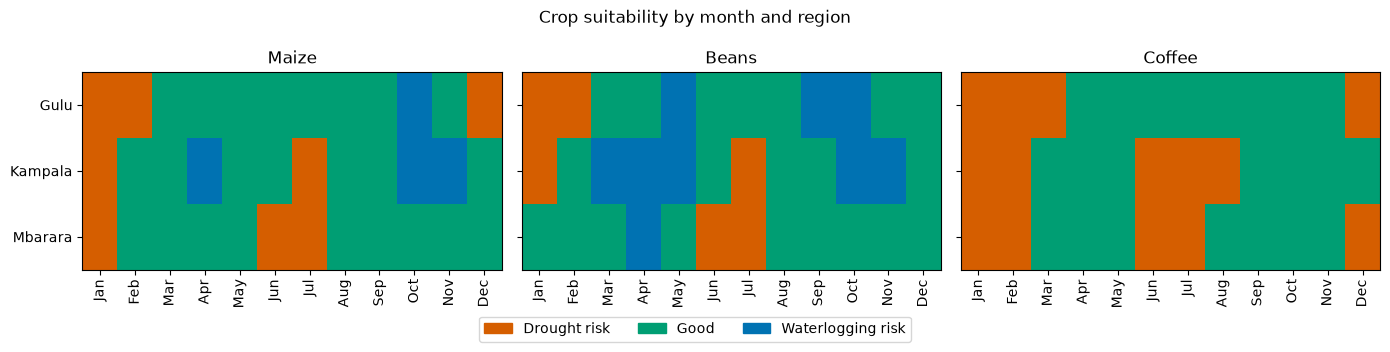

In [10]:
status_order = ["Drought risk", "Good", "Waterlogging risk"]
cmap = ListedColormap([STATUS_COLORS[s] for s in status_order])

fig, axes = plt.subplots(1, len(crops), figsize=(14, 3.2), sharey=True)
for ax, crop in zip(axes, crops):
    sub = table[table["crop"] == crop.crop]
    grid = sub.pivot(index="region", columns="month_num", values="label")
    grid = grid.reindex(columns=range(1, 13))
    status_of = lambda label: label.split(" for ")[0] if " for " in label else label
    code = grid.map(lambda v: status_order.index(status_of(v)))
    im = ax.imshow(code.values, cmap=cmap, vmin=0, vmax=2, aspect="auto")
    ax.set_xticks(range(12))
    ax.set_xticklabels(MONTH_NAMES, rotation=90)
    ax.set_yticks(range(len(grid.index)))
    ax.set_yticklabels(grid.index)
    ax.set_title(crop.crop.capitalize())

handles = [plt.Rectangle((0, 0), 1, 1, color=STATUS_COLORS[s]) for s in status_order]
fig.legend(handles, status_order, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Crop suitability by month and region")
fig.tight_layout()
plt.show()

## Task 7 — Advisory note for one region

In [11]:
gulu_maize = table[(table["region"] == "Gulu") & (table["crop"] == "maize")][["month", "rainfall_mm", "label"]]
gulu_maize

,month,rainfall_mm,label
36,Jan,23.072857,Drought risk for maize
39,Feb,11.709286,Drought risk for maize
42,Mar,69.262857,Good for maize
45,Apr,130.135714,Good for maize
48,May,164.078571,Good for maize
51,Jun,111.214286,Good for maize
54,Jul,113.880714,Good for maize
57,Aug,148.113571,Good for maize
60,Sep,177.407143,Good for maize
63,Oct,204.422857,Waterlogging risk for maize


**Advisory note — Gulu, maize (≤200 words).**

Gulu's rainfall runs almost as one long wet season: from the classified table above, **March through November is "Good for maize" in every month except October**, with only Dec–Feb dry and unsuitable to plant into. Two peaks stand out (May and October) but the dip between them (Jun–Jul) is shallow, not a real dry break, so treat this as one extended planting window rather than two separate cropping seasons. **Plant in early-to-mid March**, right as rainfall crosses the drought threshold (Feb averages only 12 mm; March jumps to 69 mm) — planting into Feb risks the seed failing to germinate. At 90–120 days to maturity, a March planting reaches harvest around June–July, comfortably inside the "Good" band, avoiding both the Dec–Feb dry spell and October's waterlogging risk (the wettest month, 204 mm — above maize's 180 mm/month ceiling here). If attempting a **second crop**, plant again by early July so maturity falls before October; do not plant a cycle that would flower or set grain during October itself, since that month alone crosses into the waterlogging band and risks root damage and disease pressure. Avoid low-lying, poorly-drained plots for any October-adjacent harvest window.

## Extension — Year-to-year variability (real 14-year data, box plots per month)

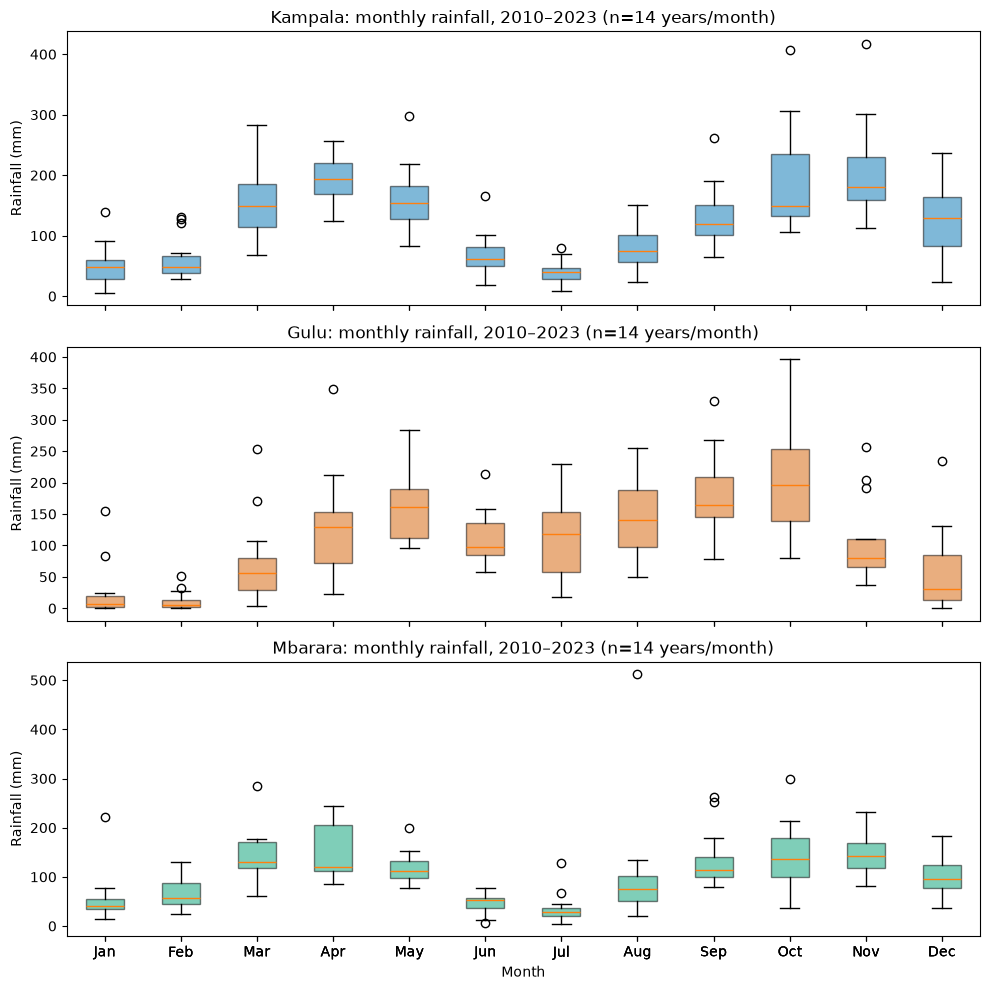

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
for ax, region_name in zip(axes, ["Kampala", "Gulu", "Mbarara"]):
    sub = raw[raw["region"] == region_name]
    data_by_month = [sub[sub["month"] == m]["rainfall_mm"].to_numpy() for m in range(1, 13)]
    bp = ax.boxplot(data_by_month, tick_labels=MONTH_NAMES, patch_artist=True)
    for patch in bp["boxes"]:
        patch.set_facecolor(REGION_COLORS[region_name])
        patch.set_alpha(0.5)
    ax.set_title(f"{region_name}: monthly rainfall, 2010–2023 (n=14 years/month)")
    ax.set_ylabel("Rainfall (mm)")
axes[-1].set_xlabel("Month")
fig.tight_layout()
plt.show()

## Findings & Limitations

Using 14 years of real NASA POWER data instead of a single illustrative year changed several conclusions. Cosine similarity and Pearson correlation can disagree sharply: Kampala vs Gulu scores cosine ≈ 0.894 ("very similar") but Pearson ≈ 0.470 (only weakly correlated) — cosine is picking up that both vectors point broadly the same "direction" (rain concentrated April–November for both), while Pearson is more sensitive to the exact month-by-month timing match, which differs more than cosine alone would suggest. Euclidean distance agrees with Pearson here (Kampala–Gulu, 209 mm, is the largest gap of the three pairs) — a reminder to read cosine similarity alongside at least one magnitude- or timing-sensitive measure, not alone. The peak-detection task delivered the most surprising result: all three regions, including Gulu, classified as **bimodal** at a 20 mm prominence threshold, contradicting the textbook "unimodal north" simplification — though Gulu's dip between its two peaks is much shallower than Kampala's, so it behaves more like one long wet season with two mild humps than two genuinely separate rainy seasons. Regional seasonality (CV of the mean monthly profile) is highest for Gulu (0.55) and lowest for Mbarara (0.41), but year-to-year *reliability* tells a different story: Gulu's January rainfall has an interannual CV of 1.89 (std exceeds the mean) versus 0.38 for its wettest month, May — dry months are wildly less predictable across years than wet ones, a genuine planting-timing risk the single-year illustrative data could never reveal. Limitations: crop thresholds are approximate FAO-derived bands, not site-calibrated agronomic trial data; the 14-year mean smooths over the exact interannual variability shown separately in the box plots; and NASA POWER's satellite/reanalysis-derived precipitation is not identical to a rain-gauge record UNMA would report for the same towns.